# Level 2: Klasifikasi dan Evaluasi Model

Estimasi waktu: 2-3 jam  
Prasyarat: `01_level_light.ipynb`

## Tujuan Pembelajaran

Setelah menyelesaikan modul ini, Anda diharapkan dapat:
1. Memahami alur supervised learning untuk kasus klasifikasi.
2. Melakukan train/test split dengan stratifikasi.
3. Membangun model KNN, Decision Tree, dan Logistic Regression.
4. Menggunakan `Pipeline` untuk mencegah data leakage pada tahap preprocessing.
5. Mengevaluasi model menggunakan akurasi, precision, recall, F1-score, dan confusion matrix.
6. Menerapkan cross-validation untuk evaluasi performa yang lebih stabil.

## Konsep Klasifikasi dan Evaluasi

### Pengertian Klasifikasi

Klasifikasi adalah tugas supervised learning untuk memprediksi kategori atau label kelas dari suatu data berdasarkan fitur-fitur inputnya.

```
Fitur (Input)                    Target (Output)
[sepal_length, sepal_width,  -->  "setosa" / "versicolor" / "virginica"
 petal_length, petal_width]
```

### Algoritma yang Dipelajari

| Algoritma | Cara Kerja Singkat | Kelebihan | Catatan |
|:---|:---|:---|:---|
| **K-Nearest Neighbors (KNN)** | Menghitung jarak ke tetangga terdekat, voting mayoritas | Intuitif dan fleksibel | Sensitif terhadap skala fitur |
| **Decision Tree** | Membagi data berdasarkan ambang batas fitur secara bertingkat | Mudah diinterpretasi | Cenderung mudah overfit jika tidak dibatasi |
| **Logistic Regression** | Memodelkan probabilitas kelas dengan fungsi logistik | Cepat, stabil, menghasilkan probabilitas | Berasumsi batas keputusan linier |

### Alasan Pembagian Train dan Test Set

Untuk mengukur kemampuan generalisasi model terhadap data baru, dataset harus dipisahkan:
- **Training Set (75%):** Digunakan untuk melatih model.
- **Test Set (25%):** Disimpan untuk evaluasi akhir dan tidak boleh digunakan selama proses pelatihan atau tuning.

## 0. Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, 
    ConfusionMatrixDisplay, f1_score
)
from IPython.display import display

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.0)
plt.rcParams['figure.dpi'] = 100

## 1. Memuat Data dan Train/Test Split

Dataset yang digunakan pada bagian awal ini adalah dataset Iris. Untuk menjaga proporsi kelas tetap seimbang antara subset latih dan uji, digunakan parameter `stratify=y`.

In [2]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

print(f'Ukuran fitur X: {X.shape}')
print(f'Ukuran target y: {y.shape}')
print(f'Kelas target: {dict(enumerate(iris.target_names))}')
print()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print(f'Training set: {X_train.shape[0]} sampel')
print(f'Test set    : {X_test.shape[0]} sampel')
print()

print('Proporsi kelas pada data awal :', y.value_counts(normalize=True).sort_index().round(3).to_dict())
print('Proporsi kelas pada data train:', y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print('Proporsi kelas pada data test :', y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

Ukuran fitur X: (150, 4)
Ukuran target y: (150,)
Kelas target: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}

Training set: 112 sampel
Test set    : 38 sampel

Proporsi kelas pada data awal : {0: 0.333, 1: 0.333, 2: 0.333}
Proporsi kelas pada data train: {0: 0.339, 1: 0.33, 2: 0.33}
Proporsi kelas pada data test : {0: 0.316, 1: 0.342, 2: 0.342}


## 2. Baseline Model

Sebelum menguji algoritma klasifikasi, kita tentukan baseline menggunakan model sederhana (`DummyClassifier`). Model machine learning yang baik harus mampu mengungguli skor baseline ini.

In [3]:
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

baseline_acc = accuracy_score(y_test, dummy_pred)
print(f'Baseline accuracy (majority class): {baseline_acc:.3f}')
print(f'Model klasifikasi harus memiliki akurasi di atas {baseline_acc:.1%}.')

Baseline accuracy (majority class): 0.316
Model klasifikasi harus memiliki akurasi di atas 31.6%.


## 3. Model 1: K-Nearest Neighbors (KNN)

KNN mengklasifikasikan sampel baru berdasarkan mayoritas kelas dari K tetangga terdekatnya.

Karena KNN menggunakan perhitungan jarak (Euclidean), fitur dengan skala yang lebih besar dapat mendominasi hasil. Oleh sebab itu, fitur perlu distandardisasi menggunakan `StandardScaler`.

Untuk mencegah data leakage, `StandardScaler` dan model KNN digabungkan ke dalam satu `Pipeline`. Penskalaan hanya dihitung berdasarkan data training saat pemanggilan `.fit()`.

In [4]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train, y_train)
y_pred_knn = knn_pipeline.predict(X_test)

acc_knn = accuracy_score(y_test, y_pred_knn)
print(f'KNN Accuracy: {acc_knn:.3f} (baseline: {baseline_acc:.3f})')
print(f'Selisih dengan baseline: +{(acc_knn - baseline_acc):.1%}\n')
print('Classification Report:')
print(classification_report(y_test, y_pred_knn, target_names=iris.target_names, zero_division=0))

KNN Accuracy: 0.921 (baseline: 0.316)
Selisih dengan baseline: +60.5%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.81      1.00      0.90        13
   virginica       1.00      0.77      0.87        13

    accuracy                           0.92        38
   macro avg       0.94      0.92      0.92        38
weighted avg       0.94      0.92      0.92        38



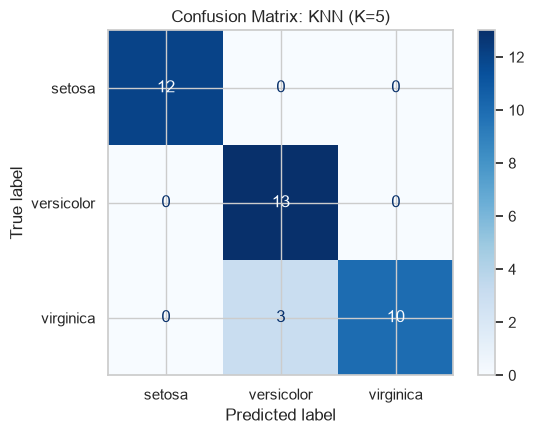

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn, 
    display_labels=iris.target_names, 
    cmap='Blues', ax=ax
)
ax.set_title('Confusion Matrix: KNN (K=5)')
plt.tight_layout()
plt.show()

## 4. Model 2: Decision Tree

Decision Tree membagi data secara hierarkis berdasarkan kondisi fitur. Model berbasis pohon tidak memerlukan penskalaan fitur karena pemisahan nilainya bersifat monotonik.

Parameter `max_depth` digunakan untuk membatasi kedalaman pohon agar model tidak mengalami overfitting.

In [6]:
dt_pipeline = Pipeline([
    ('model', DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))
])

dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)

acc_dt = accuracy_score(y_test, y_pred_dt)
print(f'Decision Tree Accuracy: {acc_dt:.3f} (baseline: {baseline_acc:.3f})\n')
print('Classification Report:')
print(classification_report(y_test, y_pred_dt, target_names=iris.target_names, zero_division=0))

Decision Tree Accuracy: 0.895 (baseline: 0.316)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.80      0.92      0.86        13
   virginica       0.91      0.77      0.83        13

    accuracy                           0.89        38
   macro avg       0.90      0.90      0.90        38
weighted avg       0.90      0.89      0.89        38



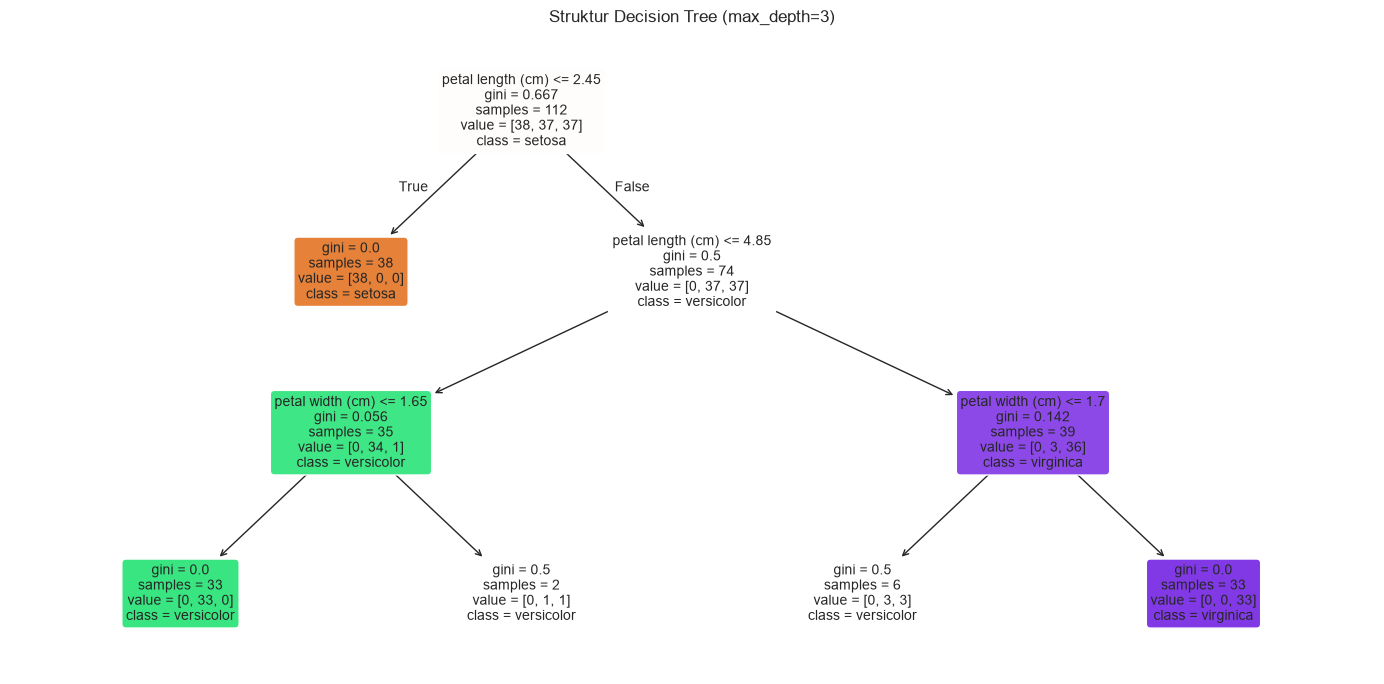

In [7]:
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(
    dt_pipeline.named_steps['model'],
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax
)
ax.set_title('Struktur Decision Tree (max_depth=3)')
plt.tight_layout()
plt.show()

In [8]:
dt_overfit = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_overfit.fit(X_train, y_train)

train_acc = accuracy_score(y_train, dt_overfit.predict(X_train))
test_acc  = accuracy_score(y_test,  dt_overfit.predict(X_test))

print('Decision Tree tanpa pembatasan max_depth:')
print(f'Training accuracy : {train_acc:.3f}')
print(f'Test accuracy     : {test_acc:.3f}')
print(f'Kedalaman pohon   : {dt_overfit.get_depth()}')
print(f'Jumlah daun (leaf): {dt_overfit.get_n_leaves()}')

if train_acc > test_acc + 0.05:
    print('Catatan: Akurasi data train jauh lebih tinggi dari data test (indikasi overfitting).')

Decision Tree tanpa pembatasan max_depth:
Training accuracy : 1.000
Test accuracy     : 0.895
Kedalaman pohon   : 6
Jumlah daun (leaf): 9
Catatan: Akurasi data train jauh lebih tinggi dari data test (indikasi overfitting).


## 5. Model 3: Logistic Regression

Logistic Regression memodelkan probabilitas keanggotaan kelas menggunakan fungsi logistik. Berbeda dari Decision Tree, model ini sensitif terhadap skala fitur sehingga membutuhkan `StandardScaler`.

In [9]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

acc_lr = accuracy_score(y_test, y_pred_lr)
print(f'Logistic Regression Accuracy: {acc_lr:.3f} (baseline: {baseline_acc:.3f})\n')
print('Classification Report:')
print(classification_report(y_test, y_pred_lr, target_names=iris.target_names, zero_division=0))

Logistic Regression Accuracy: 0.921 (baseline: 0.316)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



In [10]:
y_proba_lr = lr_pipeline.predict_proba(X_test)

proba_df = pd.DataFrame(
    y_proba_lr[:5], 
    columns=[f'P({name})' for name in iris.target_names]
)
proba_df['prediksi'] = [iris.target_names[p] for p in y_pred_lr[:5]]
proba_df['aktual'] = [iris.target_names[a] for a in y_test.values[:5]]

print('Probabilitas prediksi (5 sampel pertama):')
display(proba_df.round(3))

Probabilitas prediksi (5 sampel pertama):


,P(setosa),P(versicolor),P(virginica),prediksi,aktual
0,0.985,0.015,0.000,setosa,setosa
1,0.034,0.621,0.345,versicolor,versicolor
2,0.045,0.882,0.072,versicolor,versicolor
3,0.011,0.916,0.073,versicolor,versicolor
4,0.968,0.032,0.000,setosa,setosa


## 6. Metrik Evaluasi

Selain akurasi, performa model klasifikasi dievaluasi menggunakan metrik berikut:
- **Precision:** proporsi prediksi positif yang benar-benar positif.
- **Recall:** proporsi kasus positif riil yang berhasil terdeteksi.
- **F1-Score:** rata-rata harmonik antara precision dan recall ($2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$).

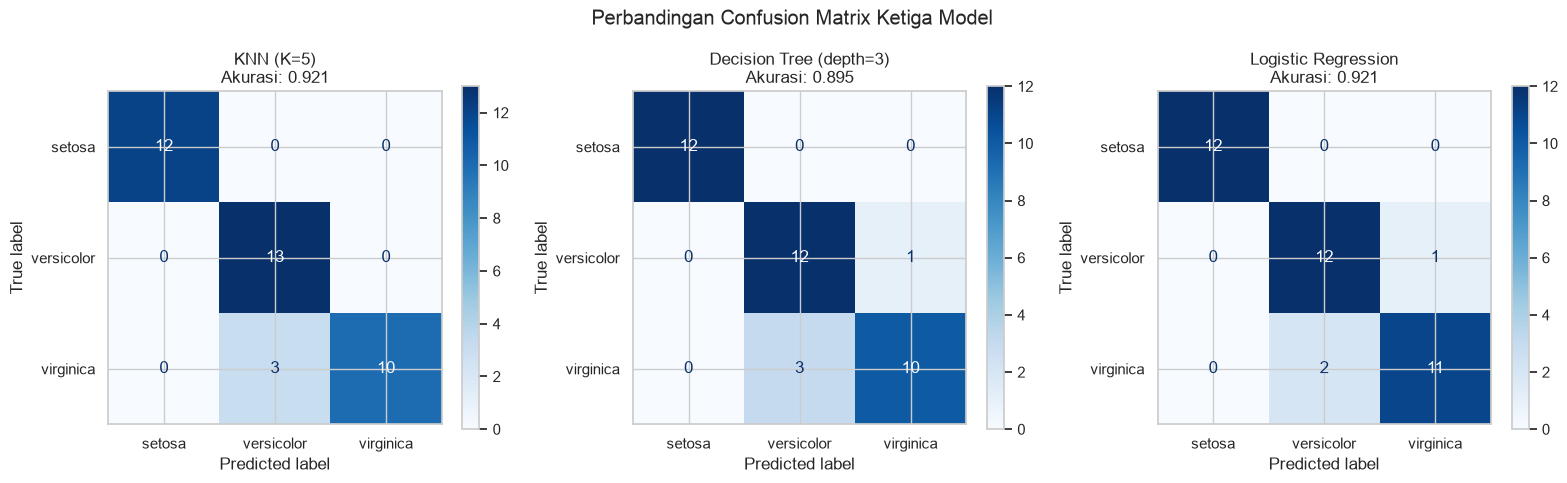

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

models_info = [
    ('KNN (K=5)', y_pred_knn),
    ('Decision Tree (depth=3)', y_pred_dt),
    ('Logistic Regression', y_pred_lr),
]

for ax, (name, y_pred) in zip(axes, models_info):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=iris.target_names,
        cmap='Blues', ax=ax
    )
    acc = accuracy_score(y_test, y_pred)
    ax.set_title(f'{name}\nAkurasi: {acc:.3f}')

plt.suptitle('Perbandingan Confusion Matrix Ketiga Model', y=1.02)
plt.tight_layout()
plt.show()

## 7. Evaluasi Menggunakan Cross-Validation

Satu kali train/test split dapat menghasilkan estimasi performa yang bervariasi bergantung pada pembagian sampel. Dengan **K-Fold Cross-Validation**, data dibagi menjadi K subset (fold), lalu setiap fold diuji secara bergantian sementara fold lainnya digunakan untuk melatih model.

`StratifiedKFold` menjaga proporsi kelas pada setiap fold agar tetap seimbang.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipelines = {
    'KNN (K=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Decision Tree (depth=3)': Pipeline([
        ('model', DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))
    ]),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
}

cv_results = {}
print('Hasil 5-Fold Cross-Validation (Stratified):')
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy')
    cv_results[name] = scores
    print(f'{name:25s}: Rata-rata = {scores.mean():.3f} (+/- {scores.std():.3f}) | Folds = {np.round(scores, 3)}')

Hasil 5-Fold Cross-Validation (Stratified):
KNN (K=5)                : Rata-rata = 0.973 (+/- 0.025) | Folds = [1.    0.967 0.933 1.    0.967]
Decision Tree (depth=3)  : Rata-rata = 0.960 (+/- 0.025) | Folds = [0.967 0.967 0.933 1.    0.933]
Logistic Regression      : Rata-rata = 0.953 (+/- 0.045) | Folds = [1.    0.967 0.9   1.    0.9  ]


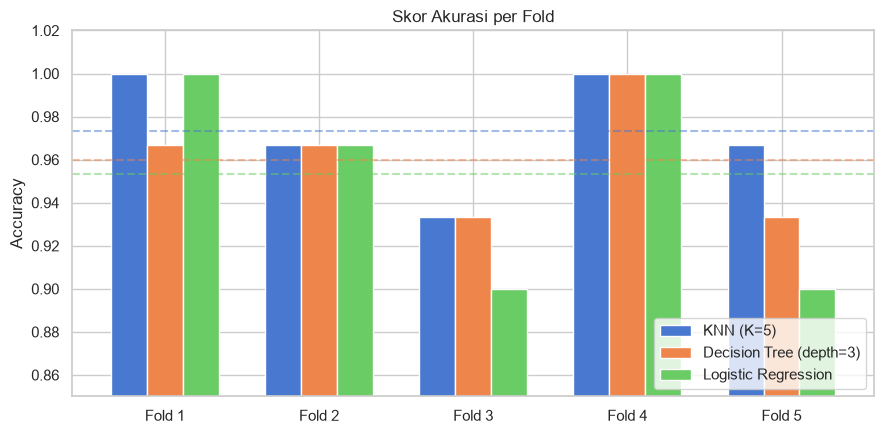

Ringkasan Perbandingan Model:


,CV Mean,CV Std,Test Acc,Baseline
KNN (K=5),0.973,0.025,0.921,0.316
Decision Tree (depth=3),0.960,0.025,0.895,0.316
Logistic Regression,0.953,0.045,0.921,0.316


In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))

cv_df = pd.DataFrame(cv_results)
cv_df.index = [f'Fold {i+1}' for i in range(5)]

cv_df.plot(kind='bar', ax=ax, width=0.7)
ax.set_ylim(0.85, 1.02)
ax.set_ylabel('Accuracy')
ax.set_title('Skor Akurasi per Fold')
ax.legend(loc='lower right')
ax.tick_params(axis='x', rotation=0)

for i, (name, scores) in enumerate(cv_results.items()):
    ax.axhline(y=scores.mean(), linestyle='--', alpha=0.5, color=f'C{i}')

plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    'CV Mean': {k: v.mean() for k, v in cv_results.items()},
    'CV Std': {k: v.std() for k, v in cv_results.items()},
    'Test Acc': {'KNN (K=5)': acc_knn, 'Decision Tree (depth=3)': acc_dt, 'Logistic Regression': acc_lr},
    'Baseline': baseline_acc
})
print('Ringkasan Perbandingan Model:')
display(summary.round(3))

## 8. Analisis Nilai K pada KNN

Nilai K menentukan jumlah tetangga yang dipertimbangkan dalam prediksi:
- Nilai K terlalu kecil (misalnya K=1) membuat model terlalu fleksibel dan rentan overfitting terhadap noise data latih.
- Nilai K terlalu besar membuat batas keputusan terlalu datar dan rentan underfitting.

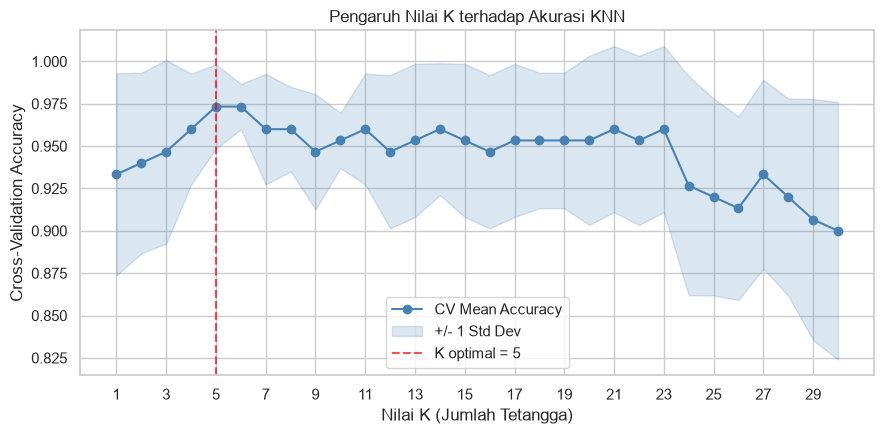

Nilai K optimal: 5 (akurasi rata-rata: 0.973)


In [14]:
k_values = range(1, 31)
cv_means = []
cv_stds = []

for k in k_values:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy')
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(k_values, cv_means, 'o-', color='steelblue', label='CV Mean Accuracy')
ax.fill_between(k_values, cv_means - cv_stds, cv_means + cv_stds, 
                alpha=0.2, color='steelblue', label='+/- 1 Std Dev')

best_k = list(k_values)[int(np.argmax(cv_means))]
ax.axvline(x=best_k, linestyle='--', color='red', alpha=0.7, label=f'K optimal = {best_k}')

ax.set_xlabel('Nilai K (Jumlah Tetangga)')
ax.set_ylabel('Cross-Validation Accuracy')
ax.set_title('Pengaruh Nilai K terhadap Akurasi KNN')
ax.legend()
ax.set_xticks(range(1, 31, 2))
plt.tight_layout()
plt.show()

print(f'Nilai K optimal: {best_k} (akurasi rata-rata: {cv_means[best_k-1]:.3f})')

## Latihan dan Pertanyaan Konsep

### Pertanyaan Evaluasi

1. Apa akibatnya jika `StandardScaler` di-fit pada seluruh data sebelum train/test split?
2. Mengapa Decision Tree tidak memerlukan `StandardScaler`?
3. Apa perbedaan antara akurasi dan F1-score, serta kapan F1-score lebih tepat digunakan?
4. Mengapa pada KNN dengan K=1 akurasi data latih selalu bernilai 100%?
5. Apa kelebihan cross-validation dibandingkan satu kali train/test split biasa?

### Pembahasan Jawaban

**1. Data Leakage pada Preprocessing**  
Jika `StandardScaler` di-fit pada seluruh dataset sebelum split, rata-rata dan standar deviasi dari data uji ikut mempengaruhi data latih. Akibatnya model mengalami data leakage (kebocoran informasi). Evaluasi performa akan tampak terlalu tinggi (over-optimistic) pada pengujian, namun berisiko turun saat diuji pada data riil. Cara yang benar adalah melakukan fit scaler hanya pada data training, atau menggabungkannya dalam `Pipeline`.

**2. Karakteristik Decision Tree terhadap Skala Fitur**  
Decision Tree bersifat scale-invariant. Algoritma ini menentukan pemisahan data berdasarkan perbandingan nilai monotonik pada tiap fitur secara individual, bukan menghitung jarak antar titik seperti KNN atau kombinasi linier terbobot seperti Logistic Regression. Oleh sebab itu, perubahan skala tidak mempengaruhi urutan maupun hasil pemisahan pohon.

**3. Akurasi vs F1-Score**  
Akurasi mengukur persentase seluruh prediksi yang benar terhadap total sampel. Metrik ini memadai jika jumlah data per kelas seimbang. Sebaliknya, F1-score adalah rata-rata harmonik antara precision dan recall. F1-score lebih relevan ketika dataset tidak seimbang (imbalanced), misalnya pada deteksi penipuan transaksi atau penyakit langka, di mana memprediksi kelas mayoritas saja bisa menghasilkan akurasi tinggi namun model gagal mendeteksi kelas target.

**4. Akurasi Data Latih pada KNN (K=1)**  
Pada K=1, saat mengevaluasi titik data latih, tetangga terdekat dari titik tersebut di ruang fitur adalah titik itu sendiri (jarak = 0). Model akan otomatis memilih label titik tersebut sehingga akurasi latih menjadi 100%. Kondisi ini mengindikasikan overfitting tinggi, karena model sekadar menghafal posisi data dan derau (noise) pada data latih.

**5. Keunggulan Cross-Validation**  
Satu kali train/test split bisa menghasilkan skor yang bias karena faktor kebetulan dalam pembagian data. Cross-validation menguji model pada beberapa kombinasi fold yang berbeda sehingga menghasilkan estimasi performa rata-rata beserta standar deviasinya. Ini memberikan gambaran yang lebih realistis dan stabil mengenai performa model.

Baseline accuracy: 0.400
KNN (K=3) accuracy: 0.956

Classification Report:
              precision    recall  f1-score   support

     class_0       0.94      1.00      0.97        15
     class_1       1.00      0.89      0.94        18
     class_2       0.92      1.00      0.96        12

    accuracy                           0.96        45
   macro avg       0.95      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



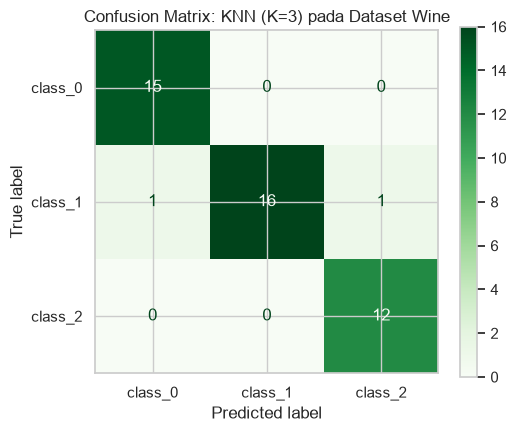

In [15]:
# Latihan 1: Evaluasi KNN (K=3) pada dataset Wine
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X_wine = wine.data
y_wine = wine.target

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.25, stratify=y_wine, random_state=RANDOM_STATE
)

# Baseline majority class
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_w, y_train_w)
baseline_wine = accuracy_score(y_test_w, dummy.predict(X_test_w))

# Pipeline KNN
knn_wine = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=3))
])

knn_wine.fit(X_train_w, y_train_w)
y_pred_knn_wine = knn_wine.predict(X_test_w)
knn_acc_wine = accuracy_score(y_test_w, y_pred_knn_wine)

print(f'Baseline accuracy: {baseline_wine:.3f}')
print(f'KNN (K=3) accuracy: {knn_acc_wine:.3f}\n')
print('Classification Report:')
print(classification_report(y_test_w, y_pred_knn_wine, target_names=wine.target_names))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test_w, y_pred_knn_wine,
    display_labels=wine.target_names,
    cmap='Greens',
    ax=ax
)
ax.set_title('Confusion Matrix: KNN (K=3) pada Dataset Wine')
plt.tight_layout()
plt.show()

KNN (K=3)                : Rata-rata = 0.9662 (+/- 0.0211)
Decision Tree (depth=3)  : Rata-rata = 0.8763 (+/- 0.0465)
Logistic Regression      : Rata-rata = 0.9833 (+/- 0.0136)


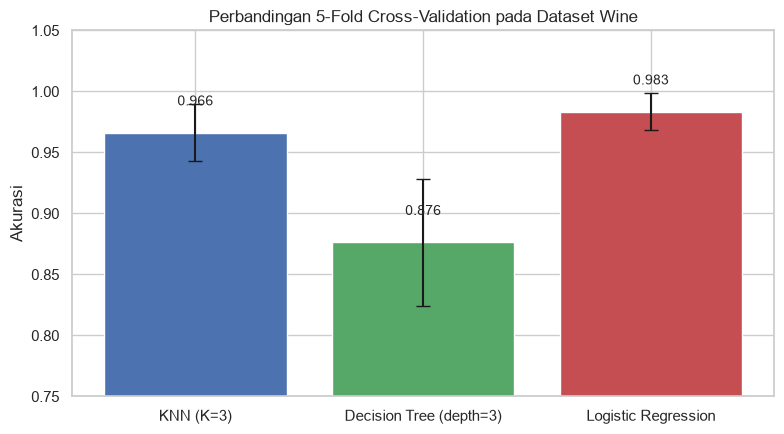

Model dengan rata-rata akurasi tertinggi: Logistic Regression (0.9833)


In [16]:
# Latihan 2: Perbandingan 3 model dengan 5-fold cross-validation pada Wine
wine_models = {
    'KNN (K=3)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=3))
    ]),
    'Decision Tree (depth=3)': Pipeline([
        ('model', DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))
    ]),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
}

cv_wine = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}

for name, model in wine_models.items():
    scores = cross_val_score(model, X_wine, y_wine, cv=cv_wine, scoring='accuracy')
    cv_scores[name] = scores
    print(f'{name:25s}: Rata-rata = {scores.mean():.4f} (+/- {scores.std():.4f})')

df_scores = pd.DataFrame(cv_scores)
means = df_scores.mean()
stds = df_scores.std()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(means.index, means.values, yerr=stds.values, capsize=5, color=['#4C72B0', '#55A868', '#C44E52'])
ax.set_ylim(0.75, 1.05)
ax.set_ylabel('Akurasi')
ax.set_title('Perbandingan 5-Fold Cross-Validation pada Dataset Wine')

for bar, m in zip(bars, means.values):
    ax.text(bar.get_x() + bar.get_width() / 2, m + 0.02, f'{m:.3f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

best_name = means.idxmax()
print(f'Model dengan rata-rata akurasi tertinggi: {best_name} ({means.max():.4f})')

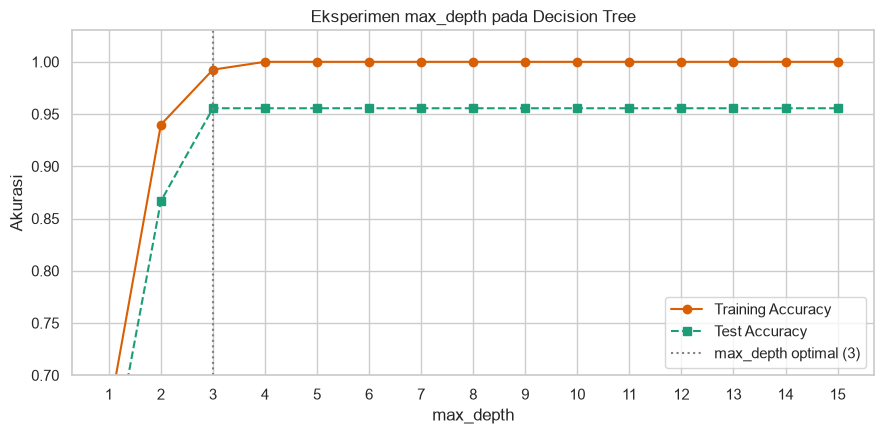

Kedalaman optimal: max_depth = 3 (test accuracy = 0.956)
Mulai max_depth = 4, training accuracy mencapai 1.000 sementara test accuracy tidak lagi bertambah.


In [17]:
# Latihan 3: Pengaruh max_depth terhadap train dan test accuracy
depth_range = range(1, 16)
train_scores = []
test_scores = []

for d in depth_range:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train_w, y_train_w)
    train_scores.append(accuracy_score(y_train_w, dt.predict(X_train_w)))
    test_scores.append(accuracy_score(y_test_w, dt.predict(X_test_w)))

best_idx = int(np.argmax(test_scores))
best_d = list(depth_range)[best_idx]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(depth_range, train_scores, 'o-', label='Training Accuracy', color='#D95F02')
ax.plot(depth_range, test_scores, 's--', label='Test Accuracy', color='#1B9E77')
ax.axvline(best_d, color='gray', linestyle=':', label=f'max_depth optimal ({best_d})')

ax.set_xlabel('max_depth')
ax.set_ylabel('Akurasi')
ax.set_title('Eksperimen max_depth pada Decision Tree')
ax.set_xticks(list(depth_range))
ax.set_ylim(0.70, 1.03)
ax.legend()
plt.tight_layout()
plt.show()

print(f'Kedalaman optimal: max_depth = {best_d} (test accuracy = {test_scores[best_idx]:.3f})')
print('Mulai max_depth = 4, training accuracy mencapai 1.000 sementara test accuracy tidak lagi bertambah.')

## Checklist Pemahaman

Sebelum melanjutkan ke level berikutnya, pastikan Anda telah memahami:
- [ ] Melakukan train/test split dengan stratifikasi (`stratify=y`).
- [ ] Menentukan baseline model dengan `DummyClassifier`.
- [ ] Menggunakan `Pipeline` (scaler + model) untuk mencegah data leakage.
- [ ] Melatih dan mengevaluasi KNN, Decision Tree, dan Logistic Regression.
- [ ] Membaca confusion matrix dan classification report.
- [ ] Memahami perbedaan precision, recall, dan F1-score.
- [ ] Menjalankan cross-validation dan membaca estimasi rata-rata serta deviasinya.
- [ ] Mengidentifikasi indikasi overfitting dari perbandingan akurasi train vs test.

Modul berikutnya: `03_level_high.ipynb`